## Exploratory Data Analysis

This file performs EDA, as per the project doc's reccomendations. Comments help understand code, while inferences about the results are detailed in the report.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Load dataset and make a copy to perform EDA on
df = pd.read_csv("dataset.csv")
df1 = df.copy()

print("Dataset Shape:", df1.shape)
print(f"Number of countries: {df1.shape[0]} | Number of columns: {df1.shape[1]}\n")
df1.info()

Dataset Shape: (195, 14)
Number of countries: 195 | Number of columns: 14

<class 'pandas.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Country                         195 non-null    str    
 1   Region                          151 non-null    str    
 2   Level                           193 non-null    float64
 3   Agriculture                     183 non-null    float64
 4   Industry                        184 non-null    float64
 5   Services                        183 non-null    float64
 6   Dominant_Sector                 183 non-null    str    
 7   Access_to_electricity           195 non-null    float64
 8   Inflation_consumer_prices       175 non-null    float64
 9   Individuals_using_the_Internet  180 non-null    float64
 10  Trade                           167 non-null    float64
 11  GDP_Growth                      1

In [5]:
#First 5 rows along with a check for duplicates
display(df1.head(5))
print(f'\nDuplicate Rows: {df1.duplicated().sum()}')

#Summary Statistics and Target Class Counts
print("\nSummary Statistics")
display(df1.describe().T)
print("\nTarget Class Counts")
class_counts = pd.DataFrame({'Count': df1['Level'].value_counts(dropna=False).sort_index(),
                             'Percentage': (df1['Level'].value_counts(normalize=True, dropna=False).sort_index()*100).round(2)
                             })

display(class_counts)

,Country,Region,Level,Agriculture,Industry,Services,Dominant_Sector,Access_to_electricity,Inflation_consumer_prices,Individuals_using_the_Internet,Trade,GDP_Growth,Unemployment_total,Infant_mortality
0,AFG,SA,0.0,34.743247,13.449823,51.806930,Services,85.3,-4.644709,15.928400,66.999578,2.266944,14.008,49.9
1,ALB,ECA,2.0,16.274239,23.160712,60.565049,Services,100.0,4.758346,83.135592,82.352493,4.015417,10.669,8.3
2,DZA,AS,1.0,13.369245,37.547655,49.083100,Services,100.0,9.322174,76.197601,43.739798,4.100000,11.645,19.7
3,AND,NaN,2.0,0.478492,12.428226,87.093282,Services,100.0,NaN,94.214996,NaN,2.583555,NaN,2.5
4,AGO,SSA,1.0,20.909337,35.701247,43.389416,Services,51.1,13.644102,37.885899,53.607013,1.320166,14.051,33.0



Duplicate Rows: 0

Summary Statistics


,count,mean,std,min,25%,50%,75%,max
Level,193.0,1.248705,0.677242,0.000000,1.000000,1.000000,2.000000,2.000000
Agriculture,183.0,10.164048,10.002369,0.015094,2.436646,6.661449,16.616926,43.988089
Industry,184.0,26.105532,11.997886,2.086302,18.150735,24.531309,31.878414,78.899528
Services,183.0,63.650621,14.344016,19.331194,53.161760,64.658763,74.939407,96.947243
Access_to_electricity,195.0,86.969744,23.219572,5.400000,84.450000,100.000000,100.000000,100.000000
Inflation_consumer_prices,175.0,10.253156,20.815756,-4.644709,3.590991,5.865719,9.302624,221.341644
Individuals_using_the_Internet,180.0,71.597557,25.374604,7.172300,59.065876,81.643250,91.011101,100.000000
Trade,167.0,94.454333,61.409560,2.473729,51.617171,81.962548,115.979792,402.566968
GDP_Growth,189.0,2.970543,4.614977,-29.433272,1.187160,3.140091,4.978660,33.795011
Unemployment_total,177.0,6.746836,5.585145,0.130000,3.126000,5.141000,8.325000,34.610000



Target Class Counts


,Count,Percentage
Level,,
0.0,26,13.33
1.0,93,47.69
2.0,74,37.95
NaN,2,1.03


### Dataset Overview

- The dataset covers **195 countries** across **14 columns**, including 10 numerical predictors, 2 categorical predictors, 1 country identifier, and the target variable `Level`.
- The target variable `Level` is not evenly distributed: 1.0 accounts for 47.69% (93 countries), 2.0 for 37.95% (74), and 0.0 for 13.33% (26). There are also 2 missing target labels, which need to be removed before supervised modelling.
- `Agriculture`, `Industry`, and `Services` represent the percentage shares of GDP contributed by each sector and add up to roughly 100% for each country. `Dominant_Sector` is derived from these shares, so including all of them together could introduce redundancy.
- The features have noticeably different scales. While `Access_to_electricity` and `Individuals_using_the_Internet` are bounded between 0 and 100%, `Trade` reaches 402.56% and `Inflation_consumer_prices` ranges from -4.64% to 221.34%.


Missing Values by Feature


,Missing Count,Percentage
Region,44,22.56
Trade,28,14.36
Inflation_consumer_prices,20,10.26
Unemployment_total,18,9.23
Individuals_using_the_Internet,15,7.69
Agriculture,12,6.15
Services,12,6.15
Dominant_Sector,12,6.15
Industry,11,5.64
GDP_Growth,6,3.08


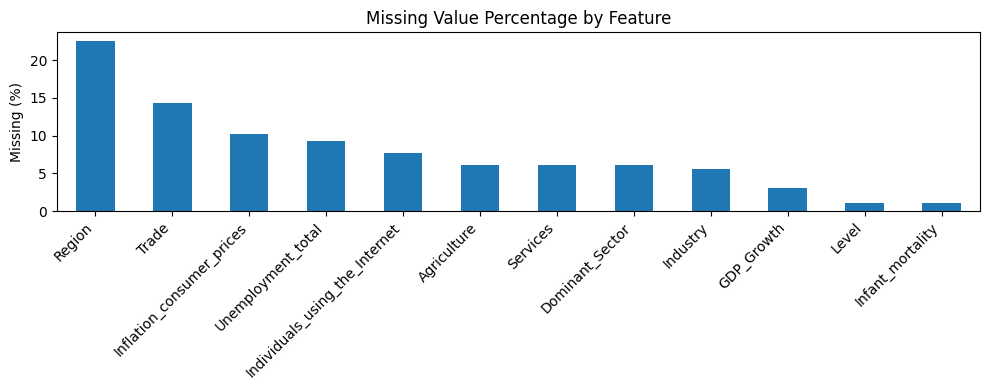

Level,0.0,1.0,2.0
Region,0.0,0.0,58.1
Agriculture,15.4,4.3,2.7
Industry,15.4,4.3,2.7
Services,15.4,4.3,2.7
Dominant_Sector,15.4,4.3,2.7
Access_to_electricity,0.0,0.0,0.0
Inflation_consumer_prices,19.2,11.8,2.7
Individuals_using_the_Internet,19.2,9.7,0.0
Trade,19.2,15.1,9.5
GDP_Growth,11.5,1.1,1.4


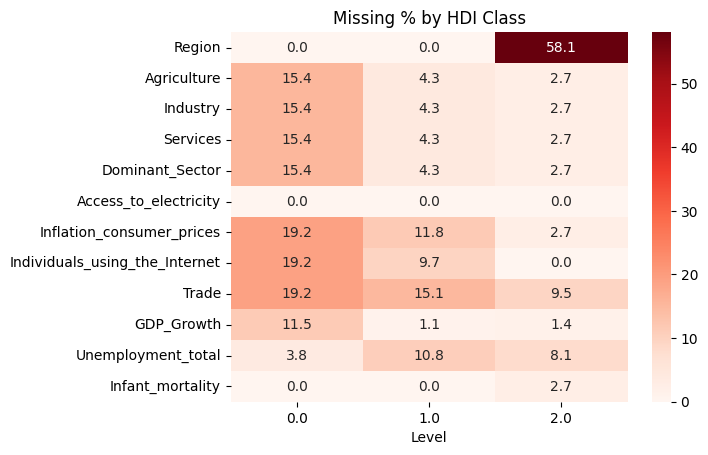

In [6]:
# Missing Value Breakdown
print("\nMissing Values by Feature")
missing_summary = pd.DataFrame({
    'Missing Count': df1.isnull().sum(),
    'Percentage': (df1.isnull().sum() / len(df1) * 100).round(2)
}).sort_values(by='Percentage', ascending=False)
display(missing_summary)

#Visualize missingness
missing_nonzero = missing_summary[missing_summary['Missing Count'] > 0]
if not missing_nonzero.empty:
    plt.figure(figsize=(10, 4))
    missing_nonzero['Percentage'].plot(kind='bar')
    plt.title("Missing Value Percentage by Feature")
    plt.ylabel("Missing (%)")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

#Missingness by HDI Target Class
feature_cols = []
for c in df1.columns:
    if c not in ['Level', 'Country']:
        feature_cols.append(c)
missing_by_class = (df1[feature_cols].isnull().groupby(df1['Level']).mean()*100).T.round(1)
display(missing_by_class)
sns.heatmap(missing_by_class, annot=True, fmt='.1f', cmap='Reds')
plt.title('Missing % by HDI Class')
plt.show()

### Missing Value Patterns

- Among the features, only `Access_to_electricity` has zero missing values across all classes. Across the dataset, `Region` has the highest missing rate at **22.56%** (44 countries), followed by `Trade` (**14.36%**), `Inflation_consumer_prices` (**10.26%**), and `Unemployment_total` (**9.23%**).
- Looking at missingness by `Level`, every labeled row with a missing `Region` belongs to **Class 2.0** (**43 out of 43**, or **58.1%** of Class 2.0, compared to **0%** in Classes 0.0 and 1.0). This shows that missingness in `Region` is systematic and strongly associated with `Level = 2.0`, rather than occurring at random.
- Most macroeconomic and digital-access metrics have noticeably higher missing rates in **Class 0.0** than in the other two classes:
  - `Inflation_consumer_prices`, `Individuals_using_the_Internet`, and `Trade` are each missing in **19.2%** of Class 0.0 countries (compared to **2.7%**, **0%**, and **9.5%**, respectively, in Class 2.0).
  - Sector shares (`Agriculture`, `Industry`, `Services`, `Dominant_Sector`) are missing in **15.4%** of Class 0.0 countries, versus **4.3%** in Class 1.0 and **2.7%** in Class 2.0.
  - `GDP_Growth` is missing in **11.5%** of Class 0.0 countries, compared to around **1.1–1.4%** in Classes 1.0 and 2.0.
- `Unemployment_total` is the one exception, with slightly more missing values in **Class 1.0 (10.8%)** and **Class 2.0 (8.1%)** than in **Class 0.0 (3.8%)**.
- Since missingness is clearly associated with `Level`, the gaps aren't completely random. Imputing with a single global mean or median could blur real differences between classes.

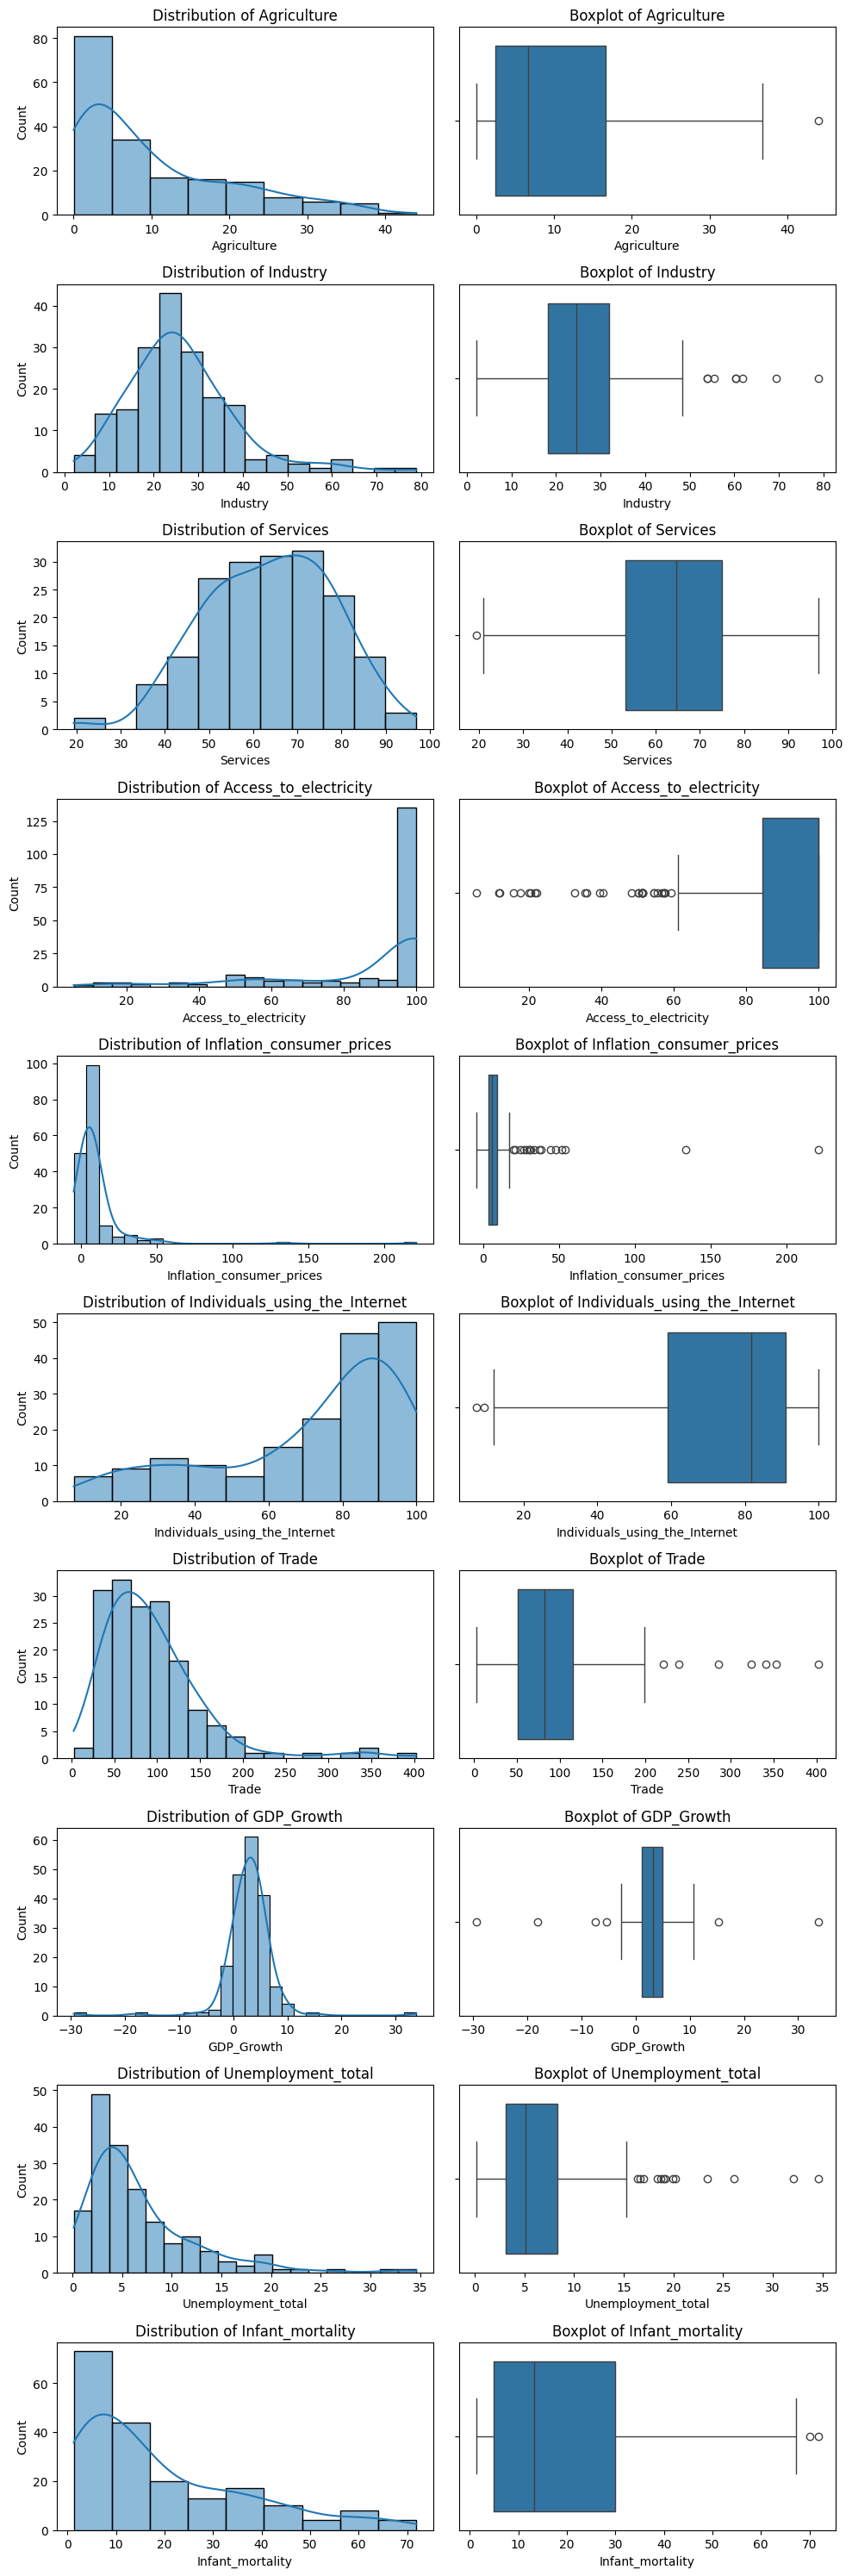

,feature,mean,median,n_outliers,examples
0,Agriculture,10.16,6.66,1,[NER]
1,Industry,26.11,24.53,8,"[BRN, GAB, GUY, IRQ, KWT]"
2,Services,63.65,64.66,1,[LBY]
3,Access_to_electricity,86.97,100.00,31,"[AGO, BEN, BFA, BDI, CAF]"
4,Inflation_consumer_prices,10.25,5.87,17,"[ARG, BDI, EGY, ETH, GHA]"
5,Individuals_using_the_Internet,71.60,81.64,2,"[BDI, UGA]"
6,Trade,94.45,81.96,7,"[DJI, HKG, IRL, LUX, MLT]"
7,GDP_Growth,2.97,3.14,6,"[GNQ, GUY, MHL, WSM, SDN]"
8,Unemployment_total,6.75,5.14,13,"[BWA, COG, DJI, SWZ, GAB]"
9,Infant_mortality,19.24,13.20,2,"[NGA, SSD]"


In [7]:
num_cols = []
for c in feature_cols:
    if c not in ['Region', 'Dominant_Sector']:
        num_cols.append(c)
plt.figure(figsize=(10, 3*len(num_cols)))
for i, col in enumerate(num_cols):
    plt.subplot(len(num_cols), 2, 2*i+1)
    sns.histplot(df1[col], kde=True)
    plt.title(f'Distribution of {col}')

    plt.subplot(len(num_cols), 2, 2*i+2)
    sns.boxplot(x=df1[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

rows = []
for c in num_cols:
    q1, q3 = df1[c].quantile(0.25), df1[c].quantile(0.75)
    iqr = q3 - q1
    out = df1[(df1[c] < q1 - 1.5*iqr) | (df1[c] > q3 + 1.5*iqr)]
    rows.append((c, df1[c].mean(), df1[c].median(), len(out), list(out['Country'][:5])))
display(pd.DataFrame(rows, columns=['feature', 'mean', 'median', 'n_outliers', 'examples']).round(2))

### Numerical Distributions & Outliers
- **Right-skewed features:** `Inflation_consumer_prices` (17 upper outliers, up to 221.3%) and `Trade` (7 upper outliers, up to 402.6%) have pronounced right tails. `Unemployment_total` (13 upper outliers), `Infant_mortality` (2 upper outliers), and `Agriculture` (1 upper outlier) are also right-skewed.
- **Left-skewed features:** `Access_to_electricity` piles up at the 100% ceiling, leaving 31 countries with lower electrification (down to 5.4%) as lower-tail outliers. `Individuals_using_the_Internet` is also left-skewed around a median of 81.6%, with 2 lower outliers (`BDI`, `UGA`).
- **Other distributions:** `Services` is roughly symmetric around its median (64.7%) with 1 low outlier (`LBY` at 19.3%). `Industry` centers around a median of 24.5% with 8 high outliers (up to 78.9%), and `GDP_Growth` clusters around its median (3.1%) with 6 two-sided outliers ranging from -29.4% to +33.8%.
- Overall, several features exhibit strong skewness and extreme values, which is worth accounting for when choosing scaling and transformation steps for scale-sensitive models.


Agriculture by HDI Class


,Level,mean,median,std
0,0.0,27.296654,28.961000,9.354818
1,1.0,12.025611,9.920603,7.580539
2,2.0,2.627987,2.139215,2.542424



Industry by HDI Class


,Level,mean,median,std
0,0.0,22.317217,22.210355,6.096174
1,1.0,27.258984,26.790780,13.159933
2,2.0,26.040100,23.694701,11.673015



Services by HDI Class


,Level,mean,median,std
0,0.0,50.386129,50.401882,10.297810
1,1.0,60.715405,60.155105,13.720098
2,2.0,71.331913,72.835945,11.729772


... (10 outputs left out)


Unemployment_total by HDI Class


,Level,mean,median,std
0,0.0,6.473760,4.469,6.345000
1,1.0,7.735530,5.316,6.765365
2,2.0,5.688735,5.224,2.994608



Infant_mortality by HDI Class


,Level,mean,median,std
0,0.0,48.330769,45.7,12.492710
1,1.0,22.259140,17.7,12.976678
2,2.0,5.138889,4.0,3.452844


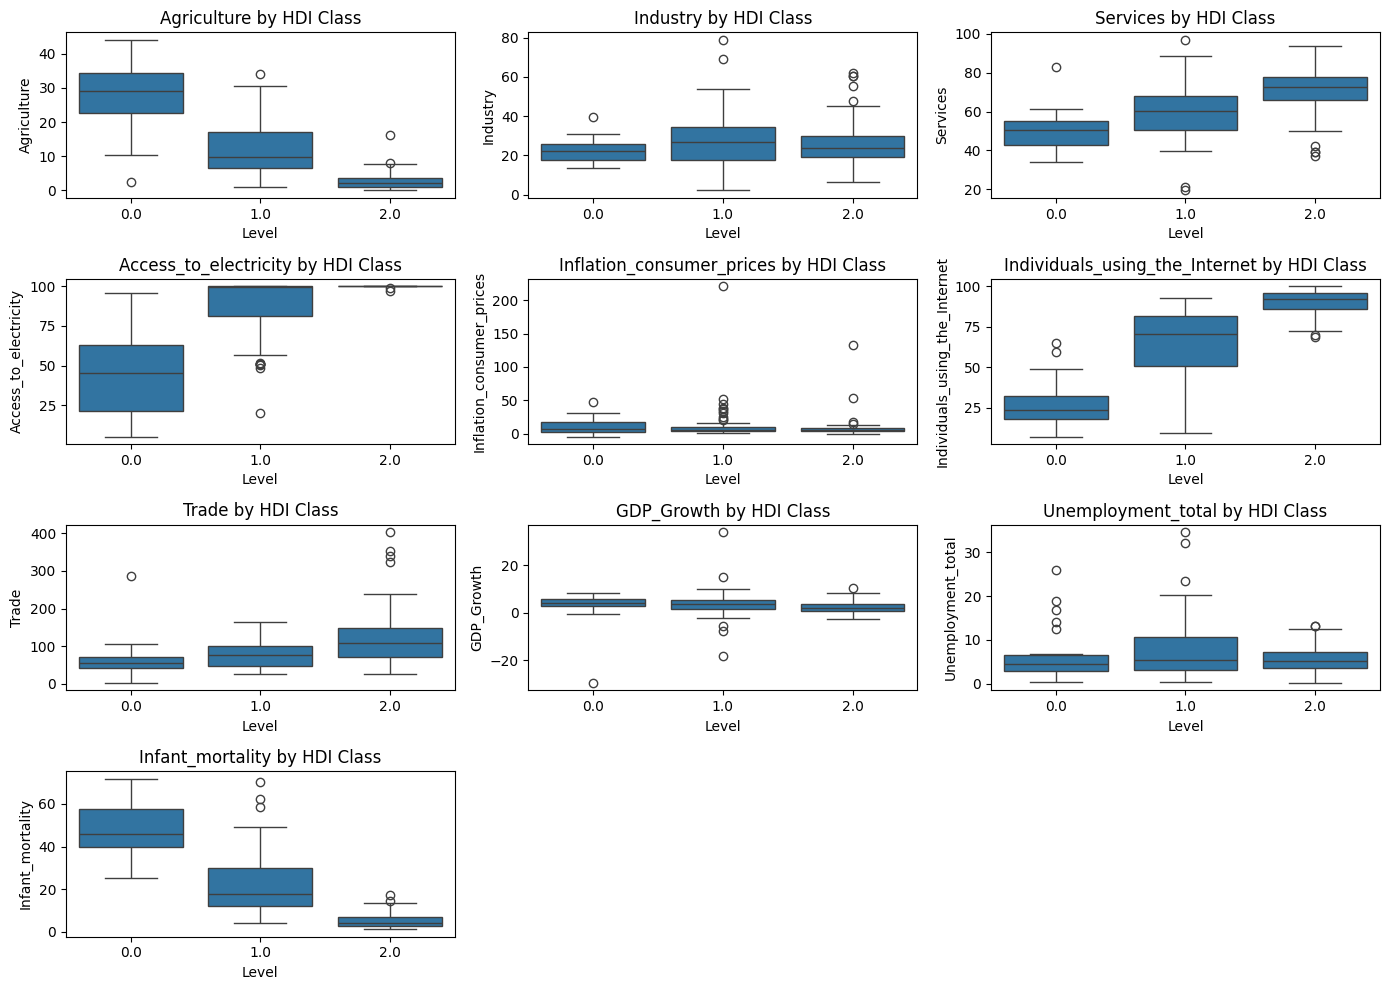

,Agriculture,Industry,Services,Access_to_electricity,Inflation_consumer_prices,Individuals_using_the_Internet,Trade,GDP_Growth,Unemployment_total,Infant_mortality
Agriculture,1.000000,-0.157947,-0.565384,-0.679987,0.049311,-0.816680,-0.435133,0.062064,-0.192869,0.740035
Industry,-0.157947,1.000000,-0.725173,-0.005307,-0.131991,0.122981,-0.068166,0.102246,0.048988,0.008778
Services,-0.565384,-0.725173,1.000000,0.475549,0.075887,0.453746,0.371108,-0.131666,0.093924,-0.521300
Access_to_electricity,-0.679987,-0.005307,0.475549,1.000000,-0.018808,0.852918,0.245598,-0.068707,-0.029365,-0.787203
Inflation_consumer_prices,0.049311,-0.131991,0.075887,-0.018808,1.000000,-0.034225,-0.126440,-0.113694,0.034177,0.044302
Individuals_using_the_Internet,-0.816680,0.122981,0.453746,0.852918,-0.034225,1.000000,0.387575,-0.190339,-0.001429,-0.827441
Trade,-0.435133,-0.068166,0.371108,0.245598,-0.126440,0.387575,1.000000,0.027728,0.051021,-0.332145
GDP_Growth,0.062064,0.102246,-0.131666,-0.068707,-0.113694,-0.190339,0.027728,1.000000,0.079139,0.062217
Unemployment_total,-0.192869,0.048988,0.093924,-0.029365,0.034177,-0.001429,0.051021,0.079139,1.000000,0.151332
Infant_mortality,0.740035,0.008778,-0.521300,-0.787203,0.044302,-0.827441,-0.332145,0.062217,0.151332,1.000000


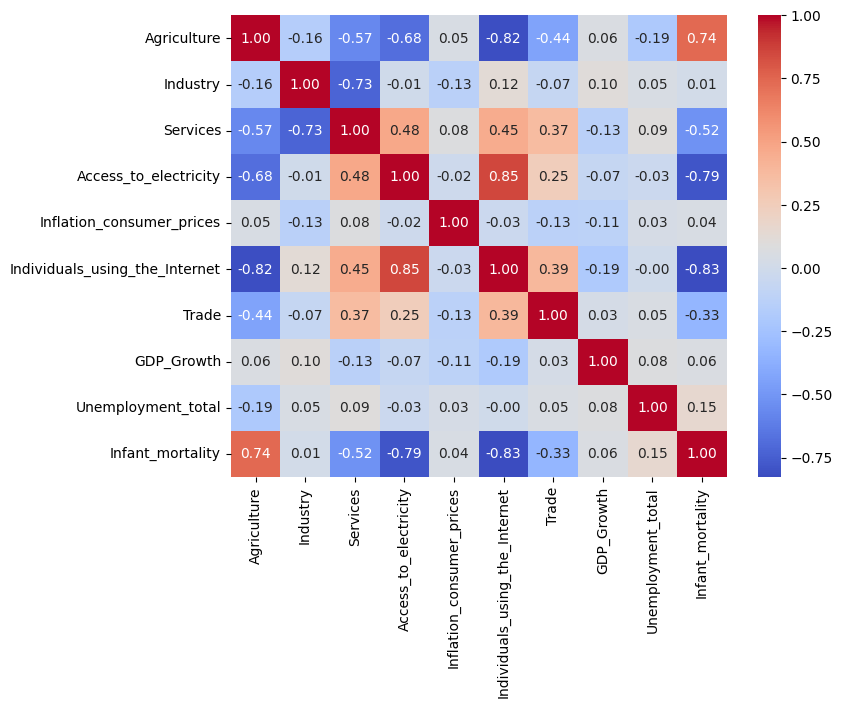

Agriculture vs Individuals_using_the_Internet: r = -0.82
Agriculture vs Infant_mortality: r = 0.74
Industry vs Services: r = -0.73
Access_to_electricity vs Individuals_using_the_Internet: r = 0.85
Access_to_electricity vs Infant_mortality: r = -0.79
Individuals_using_the_Internet vs Infant_mortality: r = -0.83


In [8]:
for col in num_cols:
    print(f"\n{col} by HDI Class")
    display(df1.groupby('Level')[col].agg(['mean', 'median', 'std']).reset_index())

plt.figure(figsize=(14, 10))
for i, col in enumerate(num_cols):
    plt.subplot(4, 3, i+1)
    sns.boxplot(data=df1, x='Level', y=col)
    plt.title(f'{col} by HDI Class')
plt.tight_layout()
plt.show()

corr = df1[num_cols].corr()
display(corr)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

for i, a in enumerate(num_cols):
    for b in num_cols[i+1:]:
        if abs(corr.loc[a, b]) > 0.7:
            print(f"{a} vs {b}: r = {corr.loc[a, b]:.2f}")

### Patterns Across HDI Classes & Feature Correlations

- **Features that distinguish HDI classes:**
  - `Individuals_using_the_Internet` (medians: **23.7% → 70.4% → 92.2%**) and `Infant_mortality` (**45.7 → 17.7 → 4.0**) show clear separation across classes.
  - `Agriculture` decreases with HDI (**29.0% → 9.9% → 2.1%**), while `Services` increases (**50.4% → 60.2% → 72.8%**). `Access_to_electricity` and `Trade` also increase across classes.

- **Features with class overlap:** `Industry`, `Inflation_consumer_prices`, `Unemployment_total`, and `GDP_Growth` overlap considerably, with differences mainly in their spread and outliers.

- **Strong correlations ($|r| > 0.7$):**
  - `Access_to_electricity` and `Individuals_using_the_Internet` are strongly positively correlated (**r = 0.85**).
  - Both are negatively correlated with `Infant_mortality` (**r = -0.79` and `-0.83**). `Individuals_using_the_Internet` and `Agriculture` are strongly negatively correlated (**r = -0.82**).
  - `Agriculture` and `Infant_mortality` are positively correlated (**r = 0.74**), while `Industry` and `Services` are negatively correlated (**r = -0.73**).

- **Weak correlations:** `Inflation_consumer_prices`, `GDP_Growth`, and `Unemployment_total` have virtually no linear correlation with other variables (all **|r| < 0.20**).

Region
SSA    46
NaN    44
LAC    33
EAP    26
AS     20
ECA    17
SA      9
Name: count, dtype: int64

Level,0.0,1.0,2.0,All
Region,,,,
AS,4,10,6,20
EAP,0,22,3,25
ECA,0,7,10,17
LAC,0,23,10,33
Missing,0,0,43,43
SA,2,7,0,9
SSA,20,24,2,46
All,26,93,74,193


Level,0.0,1.0,2.0
Region,,,
AS,0.200,0.500,0.300
EAP,0.000,0.880,0.120
ECA,0.000,0.412,0.588
LAC,0.000,0.697,0.303
Missing,0.000,0.000,1.000
SA,0.222,0.778,0.000
SSA,0.435,0.522,0.043


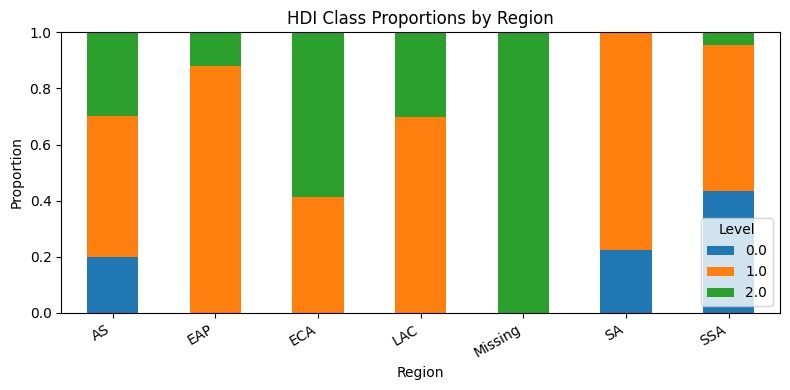

Dominant_Sector
Services       173
NaN             12
Industry         8
Agriculture      2
Name: count, dtype: int64

Level,0.0,1.0,2.0,All
Dominant_Sector,,,,
Agriculture,2,0,0,2
Industry,0,4,4,8
Missing,4,4,2,10
Services,20,85,68,173
All,26,93,74,193


Level,0.0,1.0,2.0
Dominant_Sector,,,
Agriculture,1.000,0.000,0.000
Industry,0.000,0.500,0.500
Missing,0.400,0.400,0.200
Services,0.116,0.491,0.393


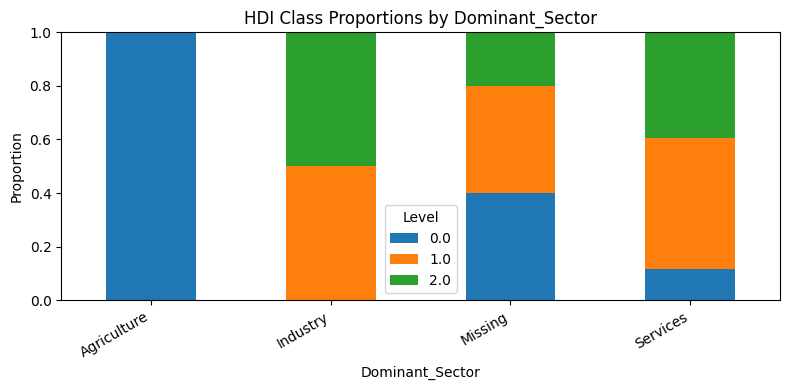

In [9]:
cat = ['Region', 'Dominant_Sector']
for col in cat:
    display(df1[col].value_counts(dropna=False))
    df2=pd.crosstab(df1[col].fillna('Missing'), df1['Level'], margins=True)
    display(df2)

    df3=pd.crosstab(df1[col].fillna('Missing'), df1['Level'], normalize='index')
    display(df3.round(3))

    df3.plot(kind='bar', stacked=True, figsize=(8, 4))
    plt.title(f'HDI Class Proportions by {col}')
    plt.ylabel('Proportion')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

### Categorical Feature Analysis

**Region:** The distribution of HDI classes varies across regions. EAP, LAC and SA are predominantly Class 1, while ECA has a higher proportion of Class 2 countries. SSA has a more mixed distribution, with a considerable share of Class 0 and Class 1 countries. Notably, all 43 labelled observations with missing region information belong to Class 2.

**Dominant Sector:** Services is the dominant sector for most countries (173 out of 193 labelled observations), with Class 1 being the largest group within this category. All 8 countries with Industry as their dominant sector belong to Class 1 or Class 2, while both countries with Agriculture as their dominant sector belong to Class 0. These smaller categories have very few observations, so their distributions should be interpreted carefully.